In [1]:
import bw2data as bd
import bw2io as bi
import bw2calc as bc
import bw2analyzer as bwa
import polars as pl 
from tqdm import tqdm

bd.projects.set_current("2026-01-13-ecoinvent-3.11-cutoff")

21:27:55+0200 [warning  ] Can't import `SimaProBlockCSVImporter` - please install `bw2io` with `pip install bw2io[multifunctional]` or install `multifunctional` and `bw_simapro_csv` manually.


In [4]:
gwps = [m for m in bd.methods if "gwp" in str(m).lower() and "no LT" not in str(m) and "EF v3.1" in str(m) and "fossil" not in str(m) and "biogenic" not in str(m) and "land" not in str(m)]
gwps

[('ecoinvent-3.11',
  'EF v3.1',
  'climate change',
  'global warming potential (GWP100)'),
 ('ecoinvent-3.11',
  'EN15804+A2 - Core impact categories and indicators',
  'climate change: total (EF v3.1 - IPCC 2021)',
  'global warming potential (GWP100)')]

In [3]:
list(bd.databases)

['ecoinvent-3.11-biosphere',
 'ecoinvent-3.11-cutoff',
 'ciogen_production',
 'ciogen_transport',
 'ciogen_fin_de_vie',
 'ciogen_custom',
 'ciogen_ponts_production',
 '2026-2-12-10h51_bernoulli_RE2020',
 '2026-3-13-17h6_processes_RE2020',
 '2026-3-18-14h52_buildings_RE2020',
 '2026-3-18-14h25_archetypes_RE2020_BB',
 '2026-3-19-11h18_processes_RE2020',
 '2026-3-19-11h27_buildings_RE2020',
 '2026-3-19-13h44_archetypes_RE2020_BB',
 '2026-3-23-10h43_archetypes_RE2020_BB',
 '2026-3-23-11h32_buildings_RE2020',
 '2026-3-23-14h9_archetypes_RE2020_BB',
 '2026-3-23-14h21_buildings_RE2020',
 '2026-3-23-15h9_archetypes_RE2020_BB']

In [3]:
arch_db = bd.Database('2026-3-23-15h9_archetypes_RE2020_BB')

In [4]:
build_db = bd.Database('2026-3-23-14h21_buildings_RE2020')

In [5]:
lots = {
    1: "VRD (Voirie et Réseaux Divers)",
    2: "Fondations et infrastructure",
    3: "Superstructure Maçonnerie",
    4: "Couverture Étanchéité Charpente – Zinguerie",
    5: "Cloisonnement Doublage – Plafonds suspendus Menuiseries intérieures",
    6: "Façades et menuiseries extérieures",
    7: "Revêtements des sols, murs et plafonds – Chape – Peintures",
    8: "CVC (Chauffage Ventilation Refroidissement – ECS)",
    9: "Installations sanitaires",
    10: "Réseaux d’énergie (courant fort)",
    11: "Réseaux de communication (courant faible)",
    12: "Appareils élévateurs et autres équipements de transport intérieur",
    13: "Équipement de production locale d’électricité",
}

sous_lots = {
    "1.1": "Réseaux (extérieurs, jusqu’au domaine public)",
    "1.2": "Stockage",
    "1.3": "Aires de stationnement extérieures",
    "2.1": "Fondations",
    "2.2": "Murs et structures enterrées (escalier de cave, parc de stationnement…)",
    "2.3": "Parcs de stationnement en superstructure (hors garages individuels)",
    "3.1": "Éléments horizontaux – Planchers, dalles, balcons",
    "3.2": "Éléments horizontaux – Poutres",
    "3.3": "Éléments verticaux – Façades",
    "3.4": "Éléments verticaux – Refends",
    "3.5": "Éléments verticaux – Poteaux",
    "3.6": "Escaliers et rampes",
    "3.7": "Éléments d’isolation",
    "3.8": "Maçonneries diverses (appuis de baie)",
    "4.1": "Toitures terrasses",
    "4.2": "Toitures en pente",
    "4.3": "Éléments techniques de toiture (cheminées, lanterneaux, etc.)",
    "5.1": "Cloisons et portes intérieures",
    "5.2": "Doublages mur, matériaux de protection, isolants et membranes",
    "5.3": "Plafonds suspendus",
    "5.4": "Planchers surélevés",
    "5.5": "Menuiseries, métalleries et quincailleries",
    "6.1": "Revêtement, isolation et doublage extérieur",
    "6.2": "Portes, fenêtres, fermetures, protections solaires",
    "6.3": "Habillages et ossatures",
    "7.1": "Revêtement des sols",
    "7.2": "Revêtement des murs et plafonds",
    "7.3": "Éléments de décoration et revêtements des menuiseries",
    "8.1": "Équipements de production (chaud/froid) – hors cogénération",
    "8.2": "Systèmes de cogénération",
    "8.3": "Systèmes d’émission",
    "8.4": "Traitement de l’air et éléments de désenfumage",
    "8.5": "Réseaux et conduits",
    "8.6": "Stockage (combustibles)",
    "8.7": "Fluides frigorigènes",
    "9.1": "Éléments sanitaires et robinetterie",
    "9.2": "Canalisations, réseaux et systèmes de traitement",
    "10.1": "Réseaux électriques",
    "10.2": "Ensemble de dispositifs pour la sécurité",
    "10.3": "Éclairage intérieur (général)",
    "10.4": "Éclairage extérieur",
    "10.5": "Systèmes d’automatisation et de contrôle",
    "10.6": "Tableaux et appareillages",
    "11.1": "Réseaux électriques et de communications",
    "11.2": "Systèmes de sécurité (personnes et biens)",
    "11.3": "Installations techniques et appareillages",
    "12.1": "Ascenseurs, monte‑charges, escaliers mécaniques, nacelles de nettoyage",
    "13.1": "Installation dédiée à la production d’électricité (panneaux, onduleur, etc.)",
}


### Cellules suivantes à ne faire que si les lots/sous_lots ne sont pas déjà sur les échanges !!!!

In [ ]:
build_db = bd.Database("2026-2-12-10h23_batiments_RE2020")

In [1]:
from archetypes_re2020.archetypes.buildings_based_archetypes_db import load_parquet_data, INPUT_PATH
from archetypes_re2020.data.source import INPUT_PATHS
df_re2020 = load_parquet_data(INPUT_PATH)

15:06:50+0200 [warning  ] Can't import `SimaProBlockCSVImporter` - please install `bw2io` with `pip install bw2io[multifunctional]` or install `multifunctional` and `bw_simapro_csv` manually.


In [ ]:
b= build_db.random()

In [ ]:
input_node.as_dict()

In [2]:
df_re2020.columns

['projet_id',
 'batiment_index',
 'zone_index',
 'lot_ref',
 'sous_lot_ref',
 'type_donnees',
 'type_declaration',
 'unite_uf_txt',
 'nomenclature_inies_1',
 'nomenclature_inies_2',
 'nomenclature_inies_3',
 'nomenclature_inies_4',
 'nomenclature_inies_5',
 'dve',
 'quantite',
 'nomenclatures',
 'usage_principal_1_txt',
 'sref',
 'puissance_thermique_max_restituable_ch_1',
 'puissance_thermique_max_restituable_ch_2',
 'quant_surf',
 'nomenclatures_UF',
 'nomenclatures_UF_dve']

In [ ]:
e = list(b.technosphere())[0]
pid,bid = b["code"].split("_")
i = e.as_dict()["input"]
input_node = bd.get_node(database = i[0],code = i[1])
# n.as_dict()
tmp = df_re2020.fill_null("None").filter(
                pl.col("projet_id") == float(pid),
                pl.col("batiment_index") ==float(bid),
                pl.col('unite_uf_txt').is_in(common_units[input_node["unit"]]),
                pl.col("dve") == float(input_node["dve"]),
                pl.col('nomenclature_inies_1') == str(input_node['nomenclature_inies_1']),
                pl.col('nomenclature_inies_2') == str(input_node['nomenclature_inies_2']),
                pl.col('nomenclature_inies_3') == str(input_node['nomenclature_inies_3']),
                pl.col('nomenclature_inies_4') == str(input_node['nomenclature_inies_4']),
                pl.col('nomenclature_inies_5') == str(input_node['nomenclature_inies_5']),
                )

tmp[EXCHANGE_METADATA[1]][0]

In [ ]:
print(input_node['nomenclature_inies_5'])

In [ ]:
meta = EXCHANGE_METADATA[0]
tmp

In [ ]:
common_units = {
    'm':          ['m', 'meter', 'metre'],
    'meter':      ['m', 'meter', 'metre'],
    'metre':      ['m', 'meter', 'metre'],

    'km':         ['km', 'kilometer', 'kilometre'],
    'kilometer':  ['km', 'kilometer', 'kilometre'],
    'kilometre':  ['km', 'kilometer', 'kilometre'],

    'kg':         ['kg', 'kilogram'],
    'kilogram':   ['kg', 'kilogram'],

    'L':          ['L', 'l', 'liter', 'litre'],
    'l':          ['L', 'l', 'liter', 'litre'],
    'liter':      ['L', 'l', 'liter', 'litre'],
    'litre':      ['L', 'l', 'liter', 'litre'],

    'm³':         ['m³', 'm^3', 'cubic meter'],
    'm^3':        ['m³', 'm^3', 'cubic meter'],
    'cubic meter':['m³', 'm^3', 'cubic meter'],

    'm²':         ['m²', 'm^2', 'sq m', 'square meter'],
    'm^2':        ['m²', 'm^2', 'sq m', 'square meter'],
    'sq m':       ['m²', 'm^2', 'sq m', 'square meter'],
    'square meter':['m²', 'm^2', 'sq m', 'square meter'],

    'u':          ['u', 'unit', 'unité', 'unite'],
    'unit':       ['u', 'unit', 'unité', 'unite'],
    'unité':      ['u', 'unit', 'unité', 'unite'],
    'unite':      ['u', 'unit', 'unité', 'unite']
}
from archetypes_re2020.buildings.buildings_db import EXCHANGE_METADATA

In [ ]:
build_db.name

In [ ]:
b= bd.get_node(database = '2026-2-12-10h23_batiments_RE2020',code ='revêtements de sol durs_céramique_m²_50')

In [ ]:
for b in tqdm(build_db) :
    print(b.as_dict())
    for e in list(b.technosphere()) :
        for meta in EXCHANGE_METADATA :
            pid,bid = b["code"].split("_")
            input_tuple = e.as_dict()["input"]
            input_node = bd.get_node(
                database = input_tuple[0],
                code = input_tuple[1]
                )
            print(input_node.as_dict())

            tmp = df_re2020.fill_null("None").filter(
                pl.col("projet_id") == float(pid),
                pl.col("batiment_index") ==float(bid),
                pl.col('unite_uf_txt').is_in(common_units[input_node["unit"]]),
                pl.col("dve") == float(input_node["dve"]),
                pl.col('nomenclature_inies_1') == str(input_node['nomenclature_inies_1']),
                pl.col('nomenclature_inies_2') == str(input_node['nomenclature_inies_2']),
                pl.col('nomenclature_inies_3') == str(input_node['nomenclature_inies_3']),
                pl.col('nomenclature_inies_4') == str(input_node['nomenclature_inies_4']),
                pl.col('nomenclature_inies_5') == str(input_node['nomenclature_inies_5'])
                )
            e[meta] = tmp[meta][0]
            e.save()

## ACV

In [6]:
lcas = {}

for ind in tqdm(gwps) : 
    for a in tqdm(arch_db) :
        lca = bc.LCA(demand={a:1.0},method=ind)
        lca.lci()
        lca.lcia()
        lcas[(ind,a['name'])] = lca

100%|██████████| 2/2 [00:42<00:00, 21.38s/it]


In [8]:
contrib_dicts = {}
for k, lca in tqdm(lcas.items()) :
    contrib_process = lca.characterized_inventory.sum(axis=0)
    nodes = [bd.get_node(id = i) for i in lca.dicts.activity.keys()] # On crée la liste des noeuds (ici des procédés) à partir de leurs indices
    contrib_dicts[k] = {nodes[i]:float(contrib_process[0,i]) for i in range(len(nodes))} # On crée un dictionnaire avec le nom des procédés pour clés et la contribution en valeur


100%|██████████| 10/10 [03:41<00:00, 22.17s/it]


In [ ]:
import simplstyles
import matplotlib.pyplot as plt
import seaborn as sns
s =1000
plt.style.use("nord-light")
cutoff = 0.01 # en pourcentage du score d'impact
fig, ax = plt.subplots()
sns.barplot( { k : v/s for k,v in contrib_dicts[list(contrib_dicts.keys())[0]].items() if v > s*cutoff},errorbar=None) # On fait ici une compréhension de dictionnaire pour ne tracer que les valeurs au dessus du cut-off
plt.xticks(rotation=45, ha='right');

In [11]:
# AC des produits de construction à l'archétype 
from collections import defaultdict

# def add_or_create(d,k,v) :
#     try :
#         d[k] += v
#     except KeyError:
#         d[k] = v

second_tier_processes = {arch: defaultdict(float) for arch in arch_db}

for arch, d in second_tier_processes.items() :
    phi_arch = list(arch.production())[0].amount
    for b in tqdm(list(arch.technosphere()),desc =f"{arch}") :
        i = b.input
        phi_b = b.amount
        for p in list(i.technosphere()) :
            d[p.input] += p.amount*phi_b/phi_arch


'Bureau' (m2, FR, None):   0%|          | 0/934 [00:00<?, ?it/s]

'Maison_individuelle_ou_accolée' (m2, FR, None): 100%|██████████| 77296/77296 [23:46<00:00, 54.18it/s]
'Enseignement_secondaire_(partie_jour)' (m2, FR, None): 100%|██████████| 44/44 [00:00<00:00, 53.50it/s]
'Enseignement_primaire' (m2, FR, None): 100%|██████████| 75/75 [00:01<00:00, 53.88it/s]


In [49]:
import numpy as np
import scipy.sparse as sp


lca = bc.LCA({arch_db.random() : 1.0},method=gwps[0])
lca.lci()
A = lca.technosphere_matrix # matrice technosphere 
mapping = lca.activity_dict # repérage id : numéro de colonne
n  = A.shape[0]

# Pour chaque archétype, on stocke son n° de colonne dans A et la valeur du 
# flux de réf
arch_ncols = []
phi_archs = {}
# phi_archs = []

for arch in arch_db:
    ncol = mapping[arch["id"]]
    phi = list(arch.production())[0].amount
    arch_ncols.append(ncol)
    # phi_archs[arch] = phi
    # phi_archs.append(phi)

num_archs = len(arch_db)
rows = arch_ncols
cols = list(range(num_archs))
data = [1.0  for phi in phi_archs]
F = sp.csc_matrix((data, (rows, cols)), shape=(n, num_archs))
# On construit le vecteur de demande finale

ValueError: all index and data arrays must have the same length

In [ ]:
reverse_mapping = {v: k for k, v in mapping.items()}
results = {}
tier2_csc = (A@A@F).tocsc()

for k, arch in enumerate(arch_db):
    col = tier2_csc.getcol(k)
    col_coo = col.tocoo()
    results[arch] = {
        reverse_mapping[row]: val / phi_archs[arch]
        for row, val in zip(col_coo.row, col_coo.data)
        if val != 0
    }


TypeError: 'float' object is not subscriptable

In [46]:
results

{'Bureau' (m2, FR, None): {292965269204459520: 2.591489583665316,
  292965269208653824: 0.5630759118689144,
  292965269208653825: 0.11412396172052801,
  292965269212848128: 3.773403688767285,
  292965269212848129: 0.017833488959058792,
  292965269217042432: 1.104713937686085,
  292965269217042433: 0.030460674670843953,
  292965269217042434: 2.449284631062541,
  292965269221236736: 0.22676569391388912,
  292965269221236737: 0.17426618147065345,
  292965269221236738: 0.023603303853772357,
  292965269225431040: 0.11342322117176923,
  292965269225431041: 0.0523703672070966,
  292965269225431042: 1.419945332682442,
  292965269225431043: 0.6589741355465847,
  292965269229625344: 0.7031641912288578,
  292965269229625345: 0.032505679276457644,
  292965269229625346: 0.013614786530530595,
  292965269233819648: 0.21619658991914503,
  292965269233819649: 0.008724827696752327,
  292965269233819650: 0.013978896634196568,
  292965269233819651: 0.722109773198652,
  292965269238013952: 0.06841052736387

In [36]:
print(A@A@F)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 81088 stored elements and shape (105428, 5)>
  Coords	Values
  (25412, 0)	21769552.20840962
  (25412, 4)	1737443.8182947899
  (25412, 2)	576366.149218432
  (25412, 1)	43444.623141028955
  (25412, 3)	24245.34072593253
  (25413, 0)	4730063.565754722
  (25413, 4)	318447.3123252306
  (25413, 2)	115317.22702321074
  (25413, 1)	9400.4938783807
  (25413, 3)	7719.1798867537045
  (25414, 0)	958687.0649858775
  (25414, 4)	221032.01007380677
  (25414, 2)	39577.1972040273
  (25414, 1)	3362.640968152572
  (25414, 3)	2971.772936695617
  (25415, 0)	31698104.875205126
  (25415, 4)	1029158.7288959085
  (25415, 2)	604905.2931712706
  (25415, 1)	81315.34773627577
  (25415, 3)	15077.623070213944
  (25416, 0)	149808.46205186422
  (25416, 4)	32005.35498627114
  (25416, 2)	2095.237999390801
  (25416, 1)	131.67999259190287
  (25416, 3)	124.7389967013128
  :	:
  (105403, 0)	-840880227.3820038
  (105404, 0)	-1728802757.2359924
  (105405, 0)	-11071730

In [28]:
list(lca.dicts.activity.items())

[(269493521226227712, 0),
 (269493521226227713, 1),
 (269493521226227714, 2),
 (269493521226227715, 3),
 (269493521226227716, 4),
 (269493521230422016, 5),
 (269493521243004928, 6),
 (269493521243004929, 7),
 (269493521243004930, 8),
 (269493521268170752, 9),
 (269493521272365056, 10),
 (269493521272365057, 11),
 (269493521310113792, 12),
 (269493521314308096, 13),
 (269493521314308097, 14),
 (269493521318502400, 15),
 (269493521318502401, 16),
 (269493521318502402, 17),
 (269493521322696704, 18),
 (269493521322696705, 19),
 (269493521322696706, 20),
 (269493521343668224, 21),
 (269493521343668225, 22),
 (269493521343668226, 23),
 (269493521343668227, 24),
 (269493521364639744, 25),
 (269493521364639745, 26),
 (269493521364639746, 27),
 (269493521368834048, 28),
 (269493521368834049, 29),
 (269493521398194176, 30),
 (269493521398194177, 31),
 (269493521427554304, 32),
 (269493521431748608, 33),
 (269493521461108736, 34),
 (269493521465303040, 35),
 (269493521465303041, 36),
 (269493521

In [ ]:
second_tier_processes

In [12]:
from datetime import datetime

today = datetime.today()

In [13]:
import pickle

with open(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/{today.year}-{today.month}-{today.day}_amounts_procedes_par_arch.pkl", "wb") as f:
    pickle.dump(second_tier_processes, f)

In [7]:
import pickle
with open("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/2026-3-23_amounts_procedes_par_arch.pkl", "rb") as f:
    second_tier_processes = pickle.load(f)

In [8]:
ind = gwps[1]
lca = bc.LCA(demand={arch_db.random() : 1.0},method=ind)
lca.lci()
contrib_proc = {arch : {} for arch in arch_db}
for k, v in second_tier_processes.items() : 
    for p,a in tqdm(v.items(),desc=f"{k}") :
        lca.redo_lcia(demand={p.id : a})
        contrib_proc[k][p] = lca.score

'Maison_individuelle_ou_accolée' (m2, FR, None): 100%|██████████| 353/353 [01:03<00:00,  5.60it/s]
'Enseignement_secondaire_(partie_jour)' (m2, FR, None): 100%|██████████| 285/285 [00:51<00:00,  5.54it/s]
'Enseignement_primaire' (m2, FR, None): 100%|██████████| 316/316 [00:56<00:00,  5.57it/s]


In [15]:
[ k for k,v in contrib_proc[list(contrib_proc.keys())[0]].items() if v <0]

['Cloisonnement_Bois' (m², FR, ('custom_process',)),
 'Bardages (vêture / vêtage / parement)_Bois' (m², FR, ('custom_process',)),
 'Contreventements_Bois' (m², FR, ('custom_process',)),
 'Charpentes_Bois' (m³, FR, ('custom_process',)),
 'Murs (éléments architecturaux)_Bois' (m², FR, ('custom_process',)),
 'Revêtements de voirie_Bois' (m², FR, ('custom_process',)),
 'Escaliers (intérieur et extérieur)_Bois' (meter, FR, ('custom_process',)),
 'Eléments porteurs horizontaux (poutres / poutrelles / entrevous / hourdis / linteaux)_Bois' (m³, FR, ('custom_process',)),
 'Isolants thermiques et acoustiques pour murs (ITI)_Laine et fibre de bois' (m², FR, ('custom_process',)),
 'Charpentes_Bois' (m², FR, ('custom_process',)),
 'Revêtements pour murs et plafonds_Bois' (m², FR, ('custom_process',))]

In [9]:
init = [ k for k in list(contrib_proc[arch_db.random()].keys())[0].as_dict().keys() if "nomenc" in k]

In [10]:
to_graph = pl.DataFrame(schema={"usage" : pl.String,"score" : pl.Float64,"indicateur" : pl.String,"procédé" : pl.String,**{k : pl.String for k in init}})

for arch,d_contrib in contrib_proc.items() :
    for p,s in d_contrib.items():
        new_row = pl.DataFrame(
            {
                "usage": str(arch),
                "score" : s,
                "indicateur" : "GWP100",
                "procédé" : p["name"],
                **{ k : v for k,v in p.as_dict().items() if "nomenc" in k}
            }
            )
        to_graph.extend(new_row)


In [11]:
to_graph.group_by(pl.col("usage")).sum()

usage,score,indicateur,procédé,nomenclature_inies_1,nomenclature_inies_2,nomenclature_inies_3,nomenclature_inies_4,nomenclature_inies_5
str,f64,str,str,str,str,str,str,str
"""'Enseignement_primaire' (m2, F…",781.203847,null,null,null,null,null,null,null
"""'Bureau' (m2, FR, None)""",831.920531,null,null,null,null,null,null,null
"""'Logement_collectif' (m2, FR, …",867.169712,null,null,null,null,null,null,null
"""'Maison_individuelle_ou_accolé…",719.449455,null,null,null,null,null,null,null
"""'Enseignement_secondaire_(part…",693.981092,null,null,null,null,null,null,null


In [12]:
phi_arch={str(arch) : list(arch.production())[0].amount for arch in arch_db}

In [13]:

scores = {str(arch) : 0 for arch in arch_db}

for arch in arch_db :
    lca = bc.LCA(demand={arch : 1.0},method=ind)
    lca.lci()
    lca.lcia()
    scores[str(arch)] = lca.score

In [14]:
to_graph = to_graph.with_columns(
    pl.struct(["usage","score"]).map_elements(
        lambda s :  s["score"]/(scores[s['usage']]),
        return_dtype = pl.Float64
    )
    .alias("score_relatif")
)

In [15]:
to_graph.group_by(pl.col("usage")).sum()

usage,score,indicateur,procédé,nomenclature_inies_1,nomenclature_inies_2,nomenclature_inies_3,nomenclature_inies_4,nomenclature_inies_5,score_relatif
str,f64,str,str,str,str,str,str,str,f64
"""'Bureau' (m2, FR, None)""",831.920531,null,null,null,null,null,null,null,1.0
"""'Maison_individuelle_ou_accolé…",719.449455,null,null,null,null,null,null,null,1.0
"""'Enseignement_secondaire_(part…",693.981092,null,null,null,null,null,null,null,1.0
"""'Logement_collectif' (m2, FR, …",867.169712,null,null,null,null,null,null,null,1.0
"""'Enseignement_primaire' (m2, F…",781.203847,null,null,null,null,null,null,null,1.0


In [16]:
cutoff = 0.004
above = to_graph.filter(pl.col("score_relatif") >= cutoff)
below = to_graph.filter(pl.col("score_relatif") < cutoff)

below = below.group_by(pl.col("usage")).sum()

below = below.with_columns(
    pl.lit("below cut-off").alias("procédé"),
    pl.lit("below cut-off").alias("nomenclature_inies_2"),
    pl.lit("GWP100").alias("indicateur")
)
to_graph_cutoff = pl.concat([above,below])



In [17]:
high_values = {k : v for k,v in res.items() if v >2000}

NameError: name 'res' is not defined

In [18]:
from archetypes_re2020.config import RAW_DATA_DIR, INTERIM_DATA_DIR
df_buildings = pl.read_csv(
    source=RAW_DATA_DIR / "202505_export_batiments_daact.csv", ignore_errors=True
    )

In [19]:
carac_high_values = {}

for k,v in high_values.items() :
    ids = k.split("_")
    tmp = df_buildings.filter(
        pl.col("batiment_index")== int(ids[1]),pl.col("projet_id")== int(ids[0])
        )
    cols = [
        'puissance_thermique_max_restituable_ch_1',
        'puissance_thermique_max_restituable_ch_2',
        "sref"
        ]
    carac_high_values[k] = {"score" : v, **{c : tmp[c][0] for c in cols}}

NameError: name 'high_values' is not defined

In [ ]:
carac_high_values

In [26]:
import altair as alt
import altair_nord_theme
alt.themes.enable("nord")


chart = alt.Chart(to_graph_cutoff,title = f"Contribution des procédés").mark_bar(stroke=None).encode(
    x=alt.X('usage:N',scale = alt.Scale(paddingInner=0.4)),
    y='score_relatif',
    color=alt.Color('nomenclature_inies_2:N')
).properties(
    width=600,
    height=300
)
# chart.configure_mark()
chart.show()


alt.Chart(...)

In [ ]:
title = "analyse_contribution_produit_nom2_gwp100"
chart.save(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/figures/{today.year}-{today.month}-{today.day}_{title}.pdf")

## ACV des procédés

In [20]:
pro_db = bd.Database("2026-3-19-11h18_processes_RE2020")

In [27]:
# df_lcas_procedes = pl.DataFrame(schema={"procede": pl.Array(pl.String, 2), "indicateur" : pl.Array(pl.String, 4), "score" : pl.Float64})
dict_lcas_procedes = {}
ind = gwps[1]
lca = bc.LCA(demand={pro_db.random() : 1.0},method=ind)
lca.lci()

for p in tqdm(pro_db) :
    lca.redo_lcia(demand={p.id : 1.0})
    dict_lcas_procedes |= {(p["database"], p["code"]) : lca.score}
    # new_row = pl.DataFrame(
    #         {
    #         "procede": [[p["database"], p["code"]]],
    #         "indicateur": [[*ind]],
    #         "score": [lca.score],
    #     }
    #     ).cast(
    #         {
    #             "procede": pl.Array(pl.String, 2),
    #             "indicateur": pl.Array(pl.String, 4),
    #         }
    #     )

    # df_lcas_procedes.extend(new_row)


100%|██████████| 367/367 [00:14<00:00, 25.25it/s]


In [ ]:
arch = arch_db.random() 
b= list(arch.technosphere())[0]
b.input["name"].split()

## AC des lots et sous-lots au GWP

In [22]:
rows_dict = {
    "archetype": [],
    "procede": [],
    "amount": [],
    "lot": [],
    "sous-lot": [],
    "pid":[],
    "bid" : []
}

for arch in arch_db:
    usage = arch["name"]
    phi_arch = list(arch.production())[0].amount
    for b in tqdm(list(arch.technosphere()),desc =f"{arch}") :
        i = b.input
        n = i["name"].split("_")
        ratio = b.amount / phi_arch
        for p in i.technosphere():
            p_dict = p.as_dict()
            rows_dict["archetype"].append(str(usage))
            rows_dict["procede"].append(p_dict["input"])
            rows_dict["amount"].append(p_dict["amount"] * ratio)
            rows_dict["lot"].append(int(p_dict["lot_ref"]))
            rows_dict["sous-lot"].append(str(p_dict["sous_lot_ref"]))
            rows_dict["pid"].append(int(n[0]))
            rows_dict["bid"].append(int(n[1]))


'Maison_individuelle_ou_accolée' (m2, FR, None): 100%|██████████| 77296/77296 [03:06<00:00, 415.20it/s]
'Enseignement_secondaire_(partie_jour)' (m2, FR, None): 100%|██████████| 44/44 [00:00<00:00, 410.16it/s]
'Logement_collectif' (m2, FR, None): 100%|██████████| 1078/1078 [00:03<00:00, 280.22it/s]


In [28]:
rows_dict["score"] = [
    rows_dict["amount"][i]*dict_lcas_procedes[rows_dict["procede"][i]] for i in range(len(rows_dict["archetype"]))
    ]

In [29]:
usages = [arch['name'] for arch in arch_db]
res_AC_lots = { u : { k : 0 for k in list(lots.keys())}for u in usages}

for i in range(len(rows_dict["archetype"])) :
    u = rows_dict["archetype"][i]
    lot = rows_dict["lot"][i]
    s = rows_dict["score"][i]
    res_AC_lots[u][lot] += s

 import des données de la base pour comparer base et modèle

In [30]:
from archetypes_re2020.archetypes.buildings_based_archetypes_db import load_parquet_data, INPUT_PATH
from archetypes_re2020.data.source import OUTPUT_PATHS

df_buildings = pl.read_csv(
    source=OUTPUT_PATHS["BUILDINGS_WO_EXTREME_OUTLIER"], ignore_errors=True
    )
df_buildings = df_buildings.filter(pl.col("mild_outliers") == False)

In [31]:
cols_to_keep = ["batiment_index","projet_id",'usage_principal_1_txt',"sref",*[c for c in df_buildings.columns if "ic_composant_" in c]]

In [32]:
to_graph_data = df_buildings.select(cols_to_keep).group_by("batiment_index","projet_id","usage_principal_1_txt","sref").sum().unpivot(index = ["batiment_index","projet_id","usage_principal_1_txt","sref"])
to_graph_data =to_graph_data.filter(pl.col("value")<10**4)
to_graph_data = to_graph_data.with_columns(
    ic_x_sref = pl.col(["value"])*pl.col("sref")
    )
to_graph_data = to_graph_data.drop_nulls("usage_principal_1_txt").group_by("usage_principal_1_txt","variable").sum()
to_graph_data = to_graph_data.with_columns(
    score = pl.col("ic_x_sref")/pl.col("sref")
    )
to_graph_data = to_graph_data.filter(~pl.col("variable").str.contains("sous")).with_columns(
    pl.col("variable").map_elements(
        lambda x : lots[int(x.split("_")[-1])],
        return_dtype = pl.String
    ).alias("lot_str")
    
).rename({"usage_principal_1_txt" : "usage"})

In [33]:
delta_data = df_buildings.select(cols_to_keep).group_by("batiment_index","projet_id","usage_principal_1_txt","sref").sum().unpivot(index = ["batiment_index","projet_id","usage_principal_1_txt","sref"])
delta_data = delta_data.filter(pl.col("variable").str.contains("sous"))


In [34]:
delta_data = delta_data.with_columns([
    pl.col("variable").str.split("_").list.get(-2).cast(pl.Int32).alias("lot"),
    (pl.col("variable").str.split("_").list.get(-2) + "." +
     pl.col("variable").str.split("_").list.get(-1)).alias("sous-lot")
])

In [35]:
i=0
data_value = delta_data.filter(
    pl.col("projet_id")==rows_dict["pid"][i],
    pl.col("batiment_index")==rows_dict["bid"][i],
    # pl.col("sous-lot") == rows_dict["sous-lot"][i]
    )
    

In [36]:
delta_data 

batiment_index,projet_id,usage_principal_1_txt,sref,variable,value,lot,sous-lot
i64,i64,str,f64,str,f64,i32,str
1,516396,"""Maison individuelle ou accolée""",97.8,"""ic_composant_sous_lot_10_1""",0.0,10,"""10.1"""
1,596668,"""Maison individuelle ou accolée""",191.0,"""ic_composant_sous_lot_10_1""",0.0,10,"""10.1"""
1,414688,"""Maison individuelle ou accolée""",115.7,"""ic_composant_sous_lot_10_1""",0.0,10,"""10.1"""
1,382033,"""Maison individuelle ou accolée""",80.6,"""ic_composant_sous_lot_10_1""",0.0,10,"""10.1"""
1,477587,"""Maison individuelle ou accolée""",146.4,"""ic_composant_sous_lot_10_1""",0.0,10,"""10.1"""
…,…,…,…,…,…,…,…
1,373593,"""Maison individuelle ou accolée""",96.6,"""ic_composant_sous_lot_9_2""",2.489,9,"""9.2"""
1,434840,"""Maison individuelle ou accolée""",109.7,"""ic_composant_sous_lot_9_2""",0.385,9,"""9.2"""
1,559919,"""Maison individuelle ou accolée""",136.3,"""ic_composant_sous_lot_9_2""",0.0,9,"""9.2"""


In [37]:
rows_dict['delta_modele-RE2020'] = []

for i in range(len(rows_dict["archetype"])) :
    data_value = delta_data.filter(
        pl.col("projet_id")==rows_dict["pid"][i],
        pl.col("batiment_index")==rows_dict["bid"][i],
        pl.col("sous-lot") == rows_dict["sous-lot"][i]
        )["value"][0]
    
    rows_dict['delta_modele-RE2020'][i] = rows_dict['score'][i] - data_value
    

IndexError: index 0 is out of bounds for sequence of length 0

In [38]:
scores_usage_data = {u : to_graph_data.filter(pl.col("usage")==u)["score"].sum() for u in to_graph_data["usage"].drop_nulls().unique()}

In [39]:
to_graph_data = to_graph_data.with_columns(
    pl.struct([pl.col("score"),pl.col("usage")]).map_elements(
        lambda s : s["score"]/scores_usage_data[s["usage"]],
        return_dtype = pl.Float64
    ).alias("score_relatif")
)
to_graph_data = to_graph_data.with_columns(
    pl.col("usage").str.replace_all(' ','_',literal=True)
)
to_graph_data = to_graph_data.with_columns(
    type = pl.lit("RE2020")
)

In [40]:
to_graph_data

usage,variable,batiment_index,projet_id,sref,value,ic_x_sref,score,lot_str,score_relatif,type
str,str,i64,i64,f64,f64,f64,f64,str,f64,str
"""Bureau""","""ic_composant_lot_1""",258,126533516,163043.5,16122.98,6.6794e6,40.967177,"""VRD (Voirie et Réseaux Divers)""",0.057865,"""RE2020"""
"""Logement_collectif""","""ic_composant_lot_8""",14110,445251916,1106962.6,101983.185,1.1776e8,106.377668,"""CVC (Chauffage Ventilation Ref…",0.112969,"""RE2020"""
"""Enseignement_primaire""","""ic_composant_lot_12""",25,11859884,10735.6,24.283,62429.1647,5.815154,"""Appareils élévateurs et autres…",0.009027,"""RE2020"""
"""Enseignement_primaire""","""ic_composant_lot_13""",25,11859884,10735.6,291.854,160466.2467,14.947115,"""Équipement de production local…",0.023202,"""RE2020"""
"""Maison_individuelle_ou_accolée""","""ic_composant_lot_9""",79558,35391711246,8.0791e6,1.8703e6,2.0421e8,25.276063,"""Installations sanitaires""",0.042021,"""RE2020"""
…,…,…,…,…,…,…,…,…,…,…
"""Enseignement_primaire""","""ic_composant_lot_3""",25,11859884,10735.6,1751.375,792406.5129,73.811106,"""Superstructure Maçonnerie""",0.114577,"""RE2020"""
"""Bureau""","""ic_composant_lot_4""",258,126533516,163043.5,15084.601,6.3153e6,38.733789,"""Couverture Étanchéité Charpent…",0.054711,"""RE2020"""
"""Enseignement_secondaire_(parti…","""ic_composant_lot_1""",31,9796113,21334.6,3547.012,1.6132e6,75.615677,"""VRD (Voirie et Réseaux Divers)""",0.068192,"""RE2020"""


In [41]:
import pandas as pd
to_graph = pd.DataFrame(res_AC_lots)
to_graph["lot"] = to_graph.index
to_graph["lot_str"] = [lots[l] for l in to_graph['lot']]
scores_usage = {u : to_graph[u].sum() for u in usages}
to_graph =to_graph.melt(id_vars = ["lot","lot_str"],var_name= "usage",value_name="score")
to_graph["score_relatif"] = to_graph["score"] / to_graph["usage"].map(scores_usage)
to_graph["type"] = ["modèle (EN15804+A2)" for _ in range(len(to_graph["lot"]))]

In [42]:
common_columns = ["lot_str","usage","score","score_relatif","type"]

In [43]:
to_graph[common_columns]

,lot_str,usage,score,score_relatif,type
0,VRD (Voirie et Réseaux Divers),Maison_individuelle_ou_accolée,28.916841,0.040193,modèle (EN15804+A2)
1,Fondations et infrastructure,Maison_individuelle_ou_accolée,85.001097,0.118147,modèle (EN15804+A2)
2,Superstructure Maçonnerie,Maison_individuelle_ou_accolée,112.071428,0.155774,modèle (EN15804+A2)
3,Couverture Étanchéité Charpente – Zinguerie,Maison_individuelle_ou_accolée,15.266292,0.021219,modèle (EN15804+A2)
4,Cloisonnement Doublage – Plafonds suspendus Me...,Maison_individuelle_ou_accolée,98.716805,0.137212,modèle (EN15804+A2)
...,...,...,...,...,...
60,Installations sanitaires,Bureau,8.830261,0.010614,modèle (EN15804+A2)
61,Réseaux d’énergie (courant fort),Bureau,2.713273,0.003261,modèle (EN15804+A2)
62,Réseaux de communication (courant faible),Bureau,0.326940,0.000393,modèle (EN15804+A2)
63,Appareils élévateurs et autres équipements de ...,Bureau,14.603183,0.017554,modèle (EN15804+A2)


In [44]:
# On fusionne données et modèle
to_graph = pd.concat([to_graph[common_columns],to_graph_data.to_pandas()[common_columns]])

In [45]:
to_graph

,lot_str,usage,score,score_relatif,type
0,VRD (Voirie et Réseaux Divers),Maison_individuelle_ou_accolée,28.916841,0.040193,modèle (EN15804+A2)
1,Fondations et infrastructure,Maison_individuelle_ou_accolée,85.001097,0.118147,modèle (EN15804+A2)
2,Superstructure Maçonnerie,Maison_individuelle_ou_accolée,112.071428,0.155774,modèle (EN15804+A2)
3,Couverture Étanchéité Charpente – Zinguerie,Maison_individuelle_ou_accolée,15.266292,0.021219,modèle (EN15804+A2)
4,Cloisonnement Doublage – Plafonds suspendus Me...,Maison_individuelle_ou_accolée,98.716805,0.137212,modèle (EN15804+A2)
...,...,...,...,...,...
60,Superstructure Maçonnerie,Enseignement_primaire,73.811106,0.114577,RE2020
61,Couverture Étanchéité Charpente – Zinguerie,Bureau,38.733789,0.054711,RE2020
62,VRD (Voirie et Réseaux Divers),Enseignement_secondaire_(partie_jour),75.615677,0.068192,RE2020
63,Équipement de production locale d’électricité,Logement_collectif,1.614960,0.001715,RE2020


In [46]:
import altair as alt
import altair_nord_theme
alt.themes.enable("nord")


chart = alt.Chart(to_graph,title =alt.Title(f"Contribution des lots")).mark_bar(stroke=None).encode(
    x=alt.X('type:N',scale = alt.Scale(paddingInner=0.1), axis=alt.Axis(labelAngle=-45,title=None)),
    y='score',
    color=alt.Color('lot_str:N'),
    column = alt.Column("usage:N",title=None,sort = [
        "Maison_individuelle_ou_accolée",
        "Logement_collectif",
        "Bureau",
        "Enseignement_primaire",
        "Enseignement_secondaire_(partie_jour)"])
).properties(
    width=150,
    height=300
)
# chart.configure_mark()
chart.configure_legend(
    labelLimit=500,
    titleLimit=0  # for the title too
)
chart.show()


alt.Chart(...)

In [55]:
from datetime import datetime
today = datetime.today()

title = "analyse_contribution_lots_gwp100_modele_vs_RE2020_absolu"
chart.save(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/figures/{today.year}-{today.month}-{today.day}_{title}.pdf")

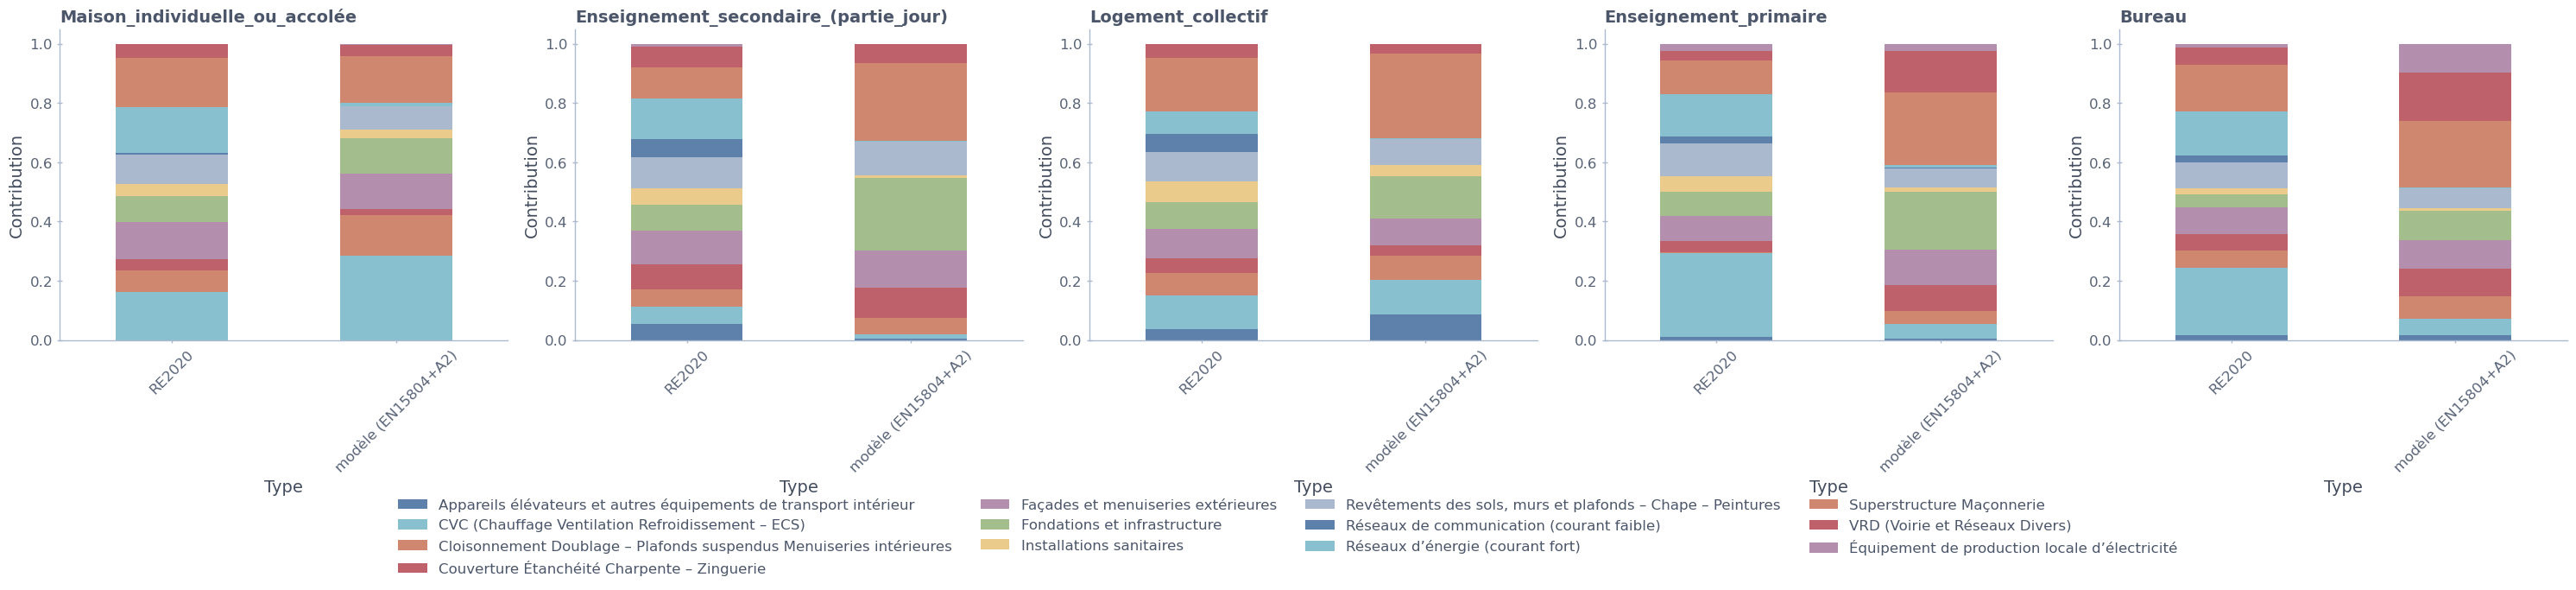

In [58]:
import matplotlib.pyplot as plt
import pandas as pd
import simplstyles
plt.style.use("nord-light")

# Get unique usages
usages = to_graph['usage'].unique()

fig, axes = plt.subplots(1, len(usages), figsize=(6 * len(usages), 6))

if len(usages) == 1:
    axes = [axes]

for ax, usage in zip(axes, usages):
    subset = to_graph[to_graph['usage'] == usage]
    
    # Pivot: index=type, columns=lot_str, values=score
    pivot = subset.pivot_table(index='type', columns='lot_str', values='score_relatif', aggfunc='sum')
    
    pivot.plot(kind='bar', stacked=True, ax=ax, legend=False)
    
    ax.set_title(usage)
    ax.set_xlabel('Type')
    ax.set_ylabel('Contribution')
    ax.tick_params(axis='x', rotation=45)

# One shared legend outside the plots
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.15))

plt.tight_layout()
# plt.show()

from datetime import datetime
today = datetime.today()

title = "analyse_contribution_lots_gwp100_modele_vs_RE2020_relatif"
plt.savefig(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/figures/{today.year}-{today.month}-{today.day}_{title}.pdf",bbox_inches='tight',dpi=300)

In [ ]:
from datetime import datetime
today = datetime.today()

title = "analyse_contribution_lots_gwp100_modele_vs_RE2020_absolu"
plt.save(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/figures/{today.year}-{today.month}-{today.day}_{title}.pdf")

In [ ]:
list(bd.databases)

In [ ]:
bureaux = [p for p in build_db if p["usage"]=='Bureau']
bureaux

In [ ]:
b_with_pump = [
    b for b in tqdm(bureaux) if any(
        "pompe" in s for s in [str(e).lower() for e in list(b.edges())])
    ]

In [ ]:
b = b_with_pump[0]

In [ ]:
list(b.edges())

In [ ]:
list(b.consumers())[0]["amount"]

In [ ]:
prodb = bd.Database('2026-3-13-17h6_processes_RE2020')

In [ ]:
pompe = prodb.search("Pompes")[0]

In [ ]:
list(pompe.edges())